![A soccer pitch for an international match.](soccer-pitch.jpg)

You're working as a sports journalist at a major online sports media company, specializing in soccer analysis and reporting. You've been watching both men's and women's international soccer matches for a number of years, and your gut instinct tells you that more goals are scored in women's international football matches than men's. This would make an interesting investigative article that your subscribers are bound to love, but you'll need to perform a valid statistical hypothesis test to be sure!

While scoping this project, you acknowledge that the sport has changed a lot over the years, and performances likely vary a lot depending on the tournament, so you decide to limit the data used in the analysis to only official `FIFA World Cup` matches (not including qualifiers) since `2002-01-01`.

You create two datasets containing the results of every official men's and women's international football match since the 19th century, which you scraped from a reliable online source. This data is stored in two CSV files: `women_results.csv` and `men_results.csv`.

The question you are trying to determine the answer to is:

> Are more goals scored in women's international soccer matches than men's?

You assume a **10% significance level**, and use the following null and alternative hypotheses:

$H_0$ : The mean number of goals scored in women's international soccer matches is the same as men's.

$H_A$ : The mean number of goals scored in women's international soccer matches is greater than men's.


Perform an appropriate hypothesis test to determine the p-value, and hence result, of whether to reject or fail to reject the null hypothesis that the mean number of goals scored in women's international soccer matches is the same as men's. Use a 10% significance level.

For this analysis, you'll use Official FIFA World Cup matches since 2002-01-01, and you'll also assume that each match is fully independent, i.e., team form is ignored.

The p-value and the result of the test must be stored in a dictionary called result_dict in the form:

result_dict = {"p_val": p_val, "result": result}

where p_val is the p-value and result is either the string "fail to reject" or "reject", depending on the result of the test. 

In [9]:
# Lets inspect the data
import pandas as pd
women_results = pd.read_csv('women_results.csv', index_col=0)
women_results.info()
print(women_results['tournament'].value_counts())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4884 entries, 0 to 4883
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        4884 non-null   object
 1   home_team   4884 non-null   object
 2   away_team   4884 non-null   object
 3   home_score  4884 non-null   int64 
 4   away_score  4884 non-null   int64 
 5   tournament  4884 non-null   object
dtypes: int64(2), object(4)
memory usage: 267.1+ KB
UEFA Euro qualification                 1445
Algarve Cup                              551
FIFA World Cup                           284
AFC Championship                         268
Cyprus Cup                               258
African Championship qualification       226
UEFA Euro                                184
African Championship                     173
FIFA World Cup qualification             172
CONCACAF Gold Cup qualification          143
AFC Asian Cup qualification              141
Copa América               

In [10]:
# Make sure we filter for only the data we need
women_fifa_result = women_results[(women_results['tournament'] == 'FIFA World Cup') & (women_results['date'] >= '2002-01-01')]

# Create a column for total goals in a match
women_fifa_result['total_goals'] = women_fifa_result['home_score'] + women_fifa_result['away_score']
women_fifa_result

,date,home_team,away_team,home_score,away_score,tournament,total_goals
1600,2003-09-20,Nigeria,North Korea,0,3,FIFA World Cup,3
1601,2003-09-20,Norway,France,2,0,FIFA World Cup,2
1602,2003-09-20,Germany,Canada,4,1,FIFA World Cup,5
1603,2003-09-20,Japan,Argentina,6,0,FIFA World Cup,6
1604,2003-09-21,United States,Sweden,3,1,FIFA World Cup,4
...,...,...,...,...,...,...,...
4465,2019-06-29,Germany,Sweden,1,2,FIFA World Cup,3
4466,2019-07-02,England,United States,1,2,FIFA World Cup,3
4467,2019-07-03,Netherlands,Sweden,1,0,FIFA World Cup,1
4468,2019-07-06,England,Sweden,1,2,FIFA World Cup,3


In [11]:
# Repeat the same process for mens football
men_results = pd.read_csv('men_results.csv', index_col=0)
men_results.info()
print(men_results['tournament'].value_counts())


<class 'pandas.core.frame.DataFrame'>
Int64Index: 44353 entries, 0 to 44352
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        44353 non-null  object
 1   home_team   44353 non-null  object
 2   away_team   44353 non-null  object
 3   home_score  44353 non-null  int64 
 4   away_score  44353 non-null  int64 
 5   tournament  44353 non-null  object
dtypes: int64(2), object(4)
memory usage: 2.4+ MB
Friendly                                17519
FIFA World Cup qualification             7878
UEFA Euro qualification                  2585
African Cup of Nations qualification     1932
FIFA World Cup                            964
                                        ...  
Real Madrid 75th Anniversary Cup            1
Évence Coppée Trophy                        1
Copa Confraternidad                         1
TIFOCO Tournament                           1
FIFA 75th Anniversary Cup                   1
Name: tournament

In [ ]:
# Filtering the data and creating the total goals column
men_fifa_result = men_results[(men_results['tournament'] == 'FIFA World Cup') & (men_results['date'] >= '2002-01-01')]
men_fifa_result['total_goals'] = men_fifa_result['home_score'] + men_fifa_result['away_score']
men_fifa_result

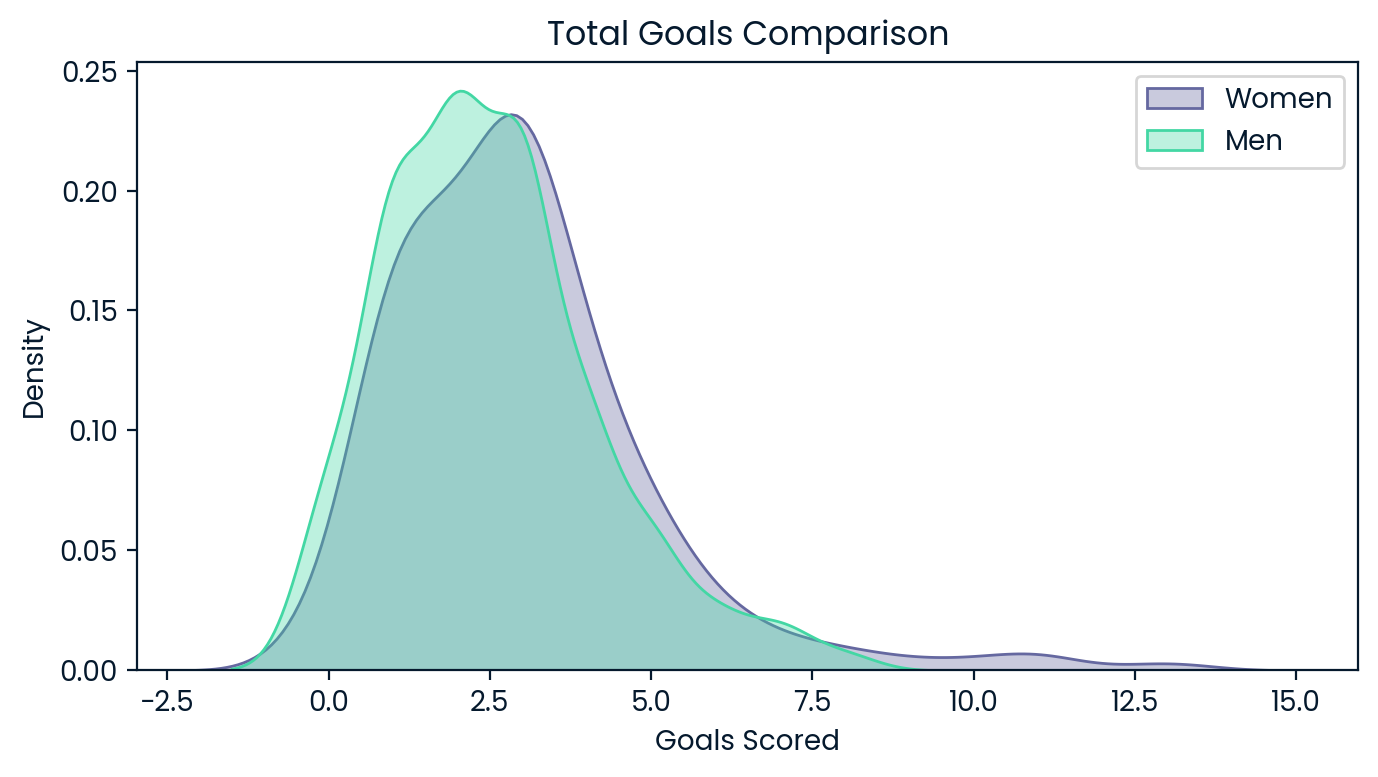

In [18]:
# Now lets inspect the distributions of the two 
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7,4))

sns.kdeplot(
    data=women_fifa_result, x="total_goals",
    fill=True, alpha=0.35, common_norm=False, label="Women", ax=ax
)
sns.kdeplot(
    data=men_fifa_result, x="total_goals",
    fill=True, alpha=0.35, common_norm=False, label="Men", ax=ax
)

ax.legend()
ax.set_title("Total Match Goals Comparison")
ax.set_xlabel("Goals Scored")
plt.tight_layout()
plt.show()



In [5]:
# Because we have a small sample size we will use the Shapiro-Wilk test for Normality
print(shapiro(women_fifa_result['total_goals']))
print(shapiro(men_fifa_result['total_goals']))

ShapiroResult(statistic=0.8491013050079346, pvalue=3.8905201759850683e-13)
ShapiroResult(statistic=0.9266489744186401, pvalue=8.894154401688226e-13)


In [19]:
# Now we test for a significant difference between the two samples using MWU test due to the samples being non-normal
import pingouin
results = pingouin.mwu(women_fifa_result['total_goals'], men_fifa_result['total_goals'], alternative='greater')
# Select the P-Value 
p_val = results['p-val'].iloc[0]

In [21]:
# Determine hypothesis test result using sig. level
if p_val <= 0.01:
    result = "reject"
else:
    result = "fail to reject"

result_dict = {"p_val": p_val, "result": result}
print(result_dict)

{'p_val': 0.005106609825443641, 'result': 'reject'}
